In [1]:
import pandas as pd

df = pd.read_csv(
    "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
print(df.shape)

print(df.columns)

df.info()

df.describe()

(20640, 10)
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [3]:
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


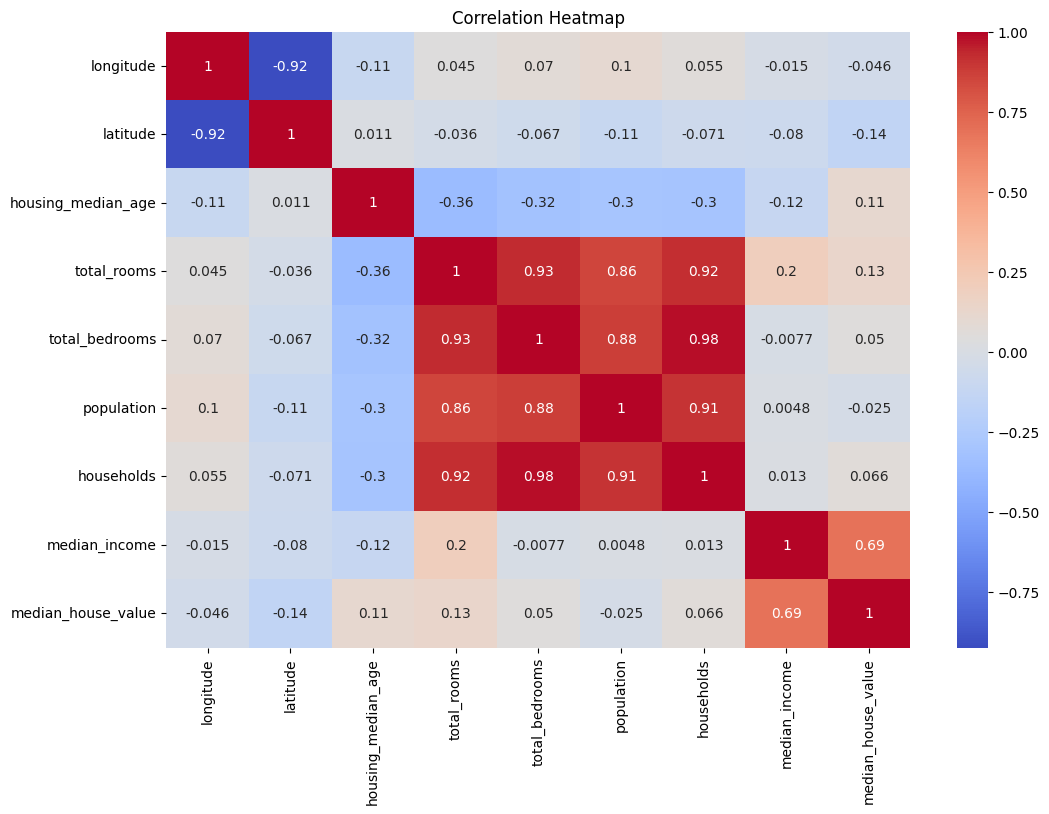

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [8]:
target_column = "median_house_value"

X = df.drop(target_column, axis=1)
y = df[target_column]

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Drop categorical column for numerical imputation and scaling
X_num = X.drop("ocean_proximity", axis=1)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_num,
    y,
    test_size=0.2,
    random_state=42
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

ols = LinearRegression()
ols.fit(X_train, y_train)

y_pred_ols = ols.predict(X_test)

print("OLS Results")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ols)))
print("MAE:", mean_absolute_error(y_test, y_pred_ols))
print("R2:", r2_score(y_test, y_pred_ols))

OLS Results
RMSE: 71131.25918417347
MAE: 51810.08933497391
R2: 0.6138872583185309


In [12]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge = Ridge()

ridge_params = {
    "alpha":[0.01,0.1,1,10,100]
}

ridge_grid = GridSearchCV(
    ridge,
    ridge_params,
    cv=5,
    scoring="r2"
)

ridge_grid.fit(X_train, y_train)

best_ridge = ridge_grid.best_estimator_

print("Best Alpha:", ridge_grid.best_params_)

Best Alpha: {'alpha': 10}


In [13]:
y_pred_ridge = best_ridge.predict(X_test)

ridge_rmse = np.sqrt(mean_squared_error(y_test,y_pred_ridge))
ridge_mae = mean_absolute_error(y_test,y_pred_ridge)
ridge_r2 = r2_score(y_test,y_pred_ridge)

print("RMSE:", ridge_rmse)
print("MAE:", ridge_mae)
print("R2:", ridge_r2)

RMSE: 71097.80564678399
MAE: 51791.56307204527
R2: 0.6142503560549781


In [14]:
from sklearn.linear_model import Lasso

lasso = Lasso(max_iter=10000)

lasso_params = {
    "alpha":[0.001,0.01,0.1,1,10]
}

lasso_grid = GridSearchCV(
    lasso,
    lasso_params,
    cv=5,
    scoring="r2"
)

lasso_grid.fit(X_train,y_train)

best_lasso = lasso_grid.best_estimator_

print("Best Alpha:", lasso_grid.best_params_)

Best Alpha: {'alpha': 10}


In [15]:
y_pred_lasso = best_lasso.predict(X_test)

lasso_rmse = np.sqrt(mean_squared_error(y_test,y_pred_lasso))
lasso_mae = mean_absolute_error(y_test,y_pred_lasso)
lasso_r2 = r2_score(y_test,y_pred_lasso)

print("RMSE:", lasso_rmse)
print("MAE:", lasso_mae)
print("R2:", lasso_r2)

RMSE: 71125.30854443446
MAE: 51807.98640150451
R2: 0.6139518578137357


In [16]:
results = pd.DataFrame({
    "Model":["OLS","Ridge","Lasso"],
    "RMSE":[
        np.sqrt(mean_squared_error(y_test,y_pred_ols)),
        ridge_rmse,
        lasso_rmse
    ],
    "MAE":[
        mean_absolute_error(y_test,y_pred_ols),
        ridge_mae,
        lasso_mae
    ],
    "R2":[
        r2_score(y_test,y_pred_ols),
        ridge_r2,
        lasso_r2
    ]
})

results

,Model,RMSE,MAE,R2
0,OLS,71131.259184,51810.089335,0.613887
1,Ridge,71097.805647,51791.563072,0.614250
2,Lasso,71125.308544,51807.986402,0.613952


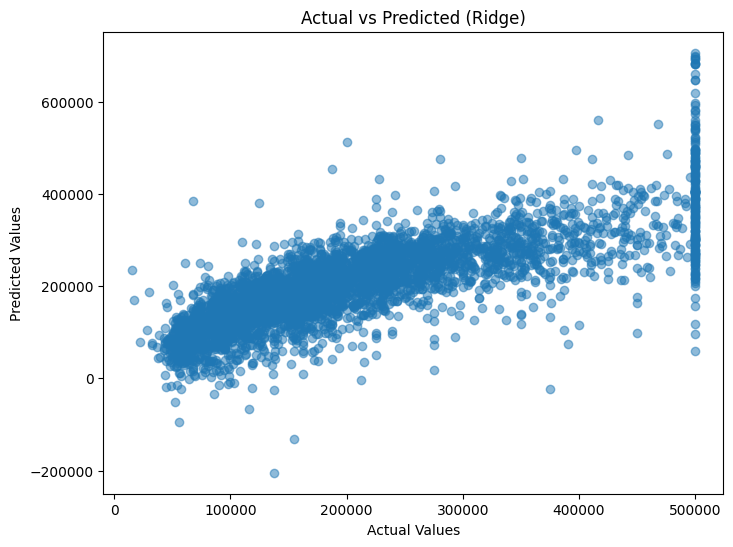

In [17]:
plt.figure(figsize=(8,6))

plt.scatter(y_test,
            y_pred_ridge,
            alpha=0.5)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted (Ridge)")

plt.show()

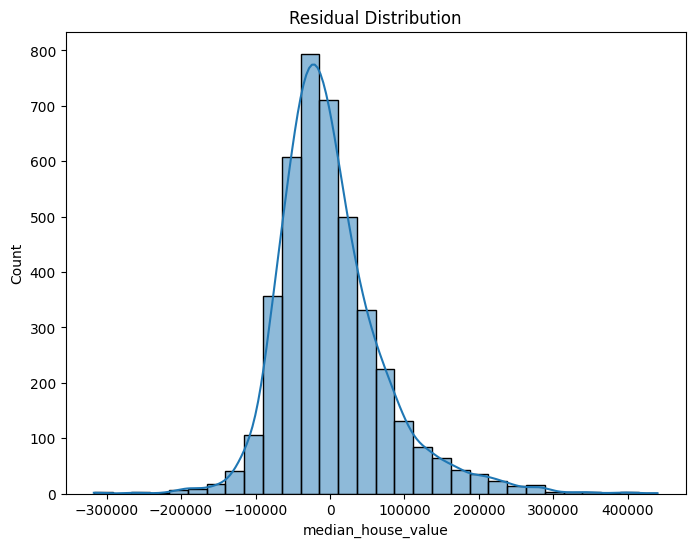

In [18]:
residuals = y_test - y_pred_ridge

plt.figure(figsize=(8,6))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.title("Residual Distribution")
plt.show()